Libraries imported successfully!

Dataset Loaded Successfully!
Dataset Shape: (2000, 7)


,Age,Income,Credit_Score,Loan_Amount,Loan_Term,Employment_Status,Loan_Approved
0,56,81788,334,15022,48,Employed,0
1,69,102879,781,21013,24,Self-Employed,1
2,46,58827,779,39687,60,Self-Employed,0
3,32,127188,364,16886,24,Unemployed,0
4,60,25655,307,26256,36,Unemployed,0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Age                2000 non-null   int64
 1   Income             2000 non-null   int64
 2   Credit_Score       2000 non-null   int64
 3   Loan_Amount        2000 non-null   int64
 4   Loan_Term          2000 non-null   int64
 5   Employment_Status  2000 non-null   str  
 6   Loan_Approved      2000 non-null   int64
dtypes: int64(6), str(1)
memory usage: 127.6 KB

Missing Values:
Age                  0
Income               0
Credit_Score         0
Loan_Amount          0
Loan_Term            0
Employment_Status    0
Loan_Approved        0
dtype: int64

Statistical Summary:


,Age,Income,Credit_Score,Loan_Amount,Loan_Term,Loan_Approved
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,43.805500,84533.585000,577.055000,25460.315000,35.47800,0.171000
std,14.929203,37771.169751,157.525951,14116.737774,16.98587,0.376603
min,18.000000,20155.000000,300.000000,1060.000000,12.00000,0.000000
25%,31.000000,50925.250000,440.000000,13444.250000,24.00000,0.000000
50%,44.000000,84073.500000,578.500000,25446.000000,36.00000,0.000000
75%,56.000000,117523.250000,715.250000,37949.250000,48.00000,0.000000
max,69.000000,149992.000000,849.000000,49994.000000,60.00000,1.000000



Loan Approval Distribution:
Loan_Approved
0    1658
1     342
Name: count, dtype: int64

Numerical Features: ['Age', 'Income', 'Credit_Score', 'Loan_Amount', 'Loan_Term']
Categorical Features: ['Employment_Status']

Training Data: (1600, 6)
Testing Data: (400, 6)

Preprocessing Pipeline Created!

Training: Logistic Regression
Logistic Regression Training Completed!

Training: Support Vector Machine
Support Vector Machine Training Completed!

Training: Decision Tree
Decision Tree Training Completed!

MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Logistic Regression,0.915,0.7656,0.7206,0.7424,0.9659
1,Support Vector Machine,0.960,0.9483,0.8088,0.8730,0.9935
2,Decision Tree,1.000,1.0000,1.0000,1.0000,1.0000


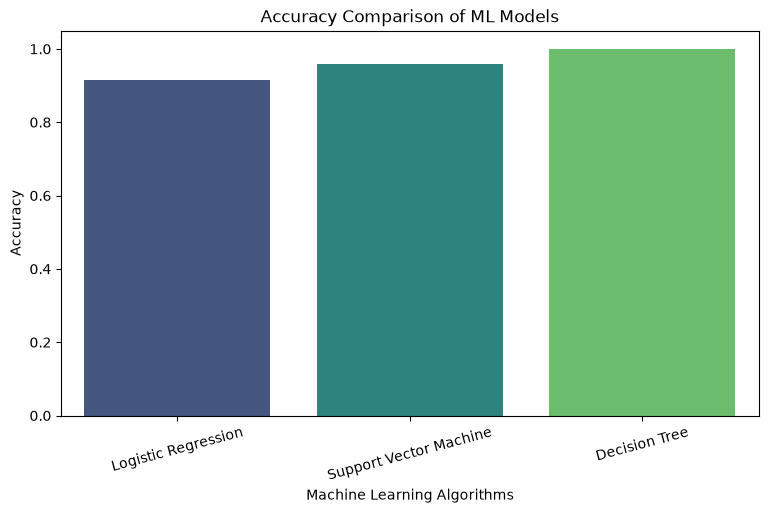

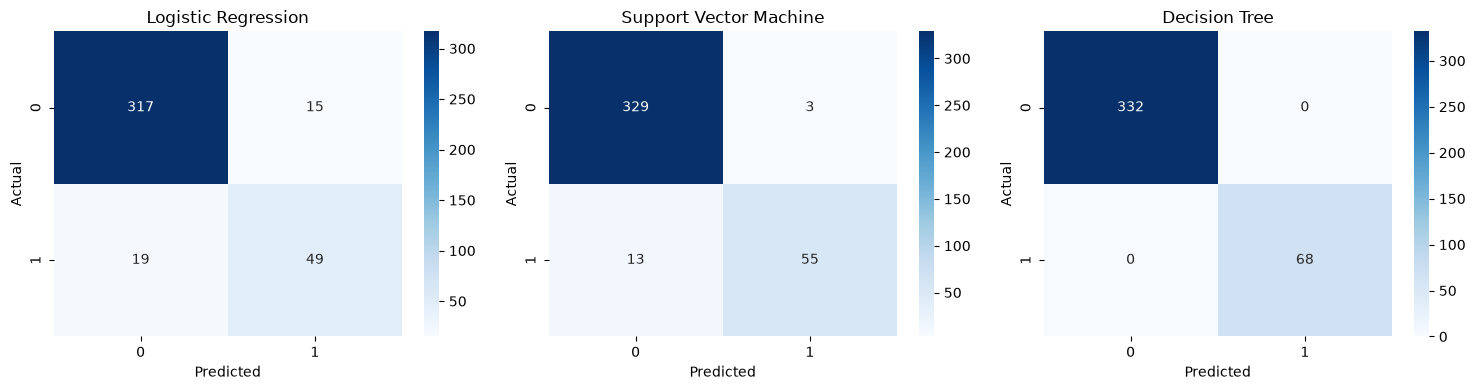


Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.95      0.95       332
           1       0.77      0.72      0.74        68

    accuracy                           0.92       400
   macro avg       0.85      0.84      0.85       400
weighted avg       0.91      0.92      0.91       400


Support Vector Machine
              precision    recall  f1-score   support

           0       0.96      0.99      0.98       332
           1       0.95      0.81      0.87        68

    accuracy                           0.96       400
   macro avg       0.96      0.90      0.92       400
weighted avg       0.96      0.96      0.96       400


Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       332
           1       1.00      1.00      1.00        68

    accuracy                           1.00       400
   macro avg       1.00      1.00      1.00       400
weighted avg  

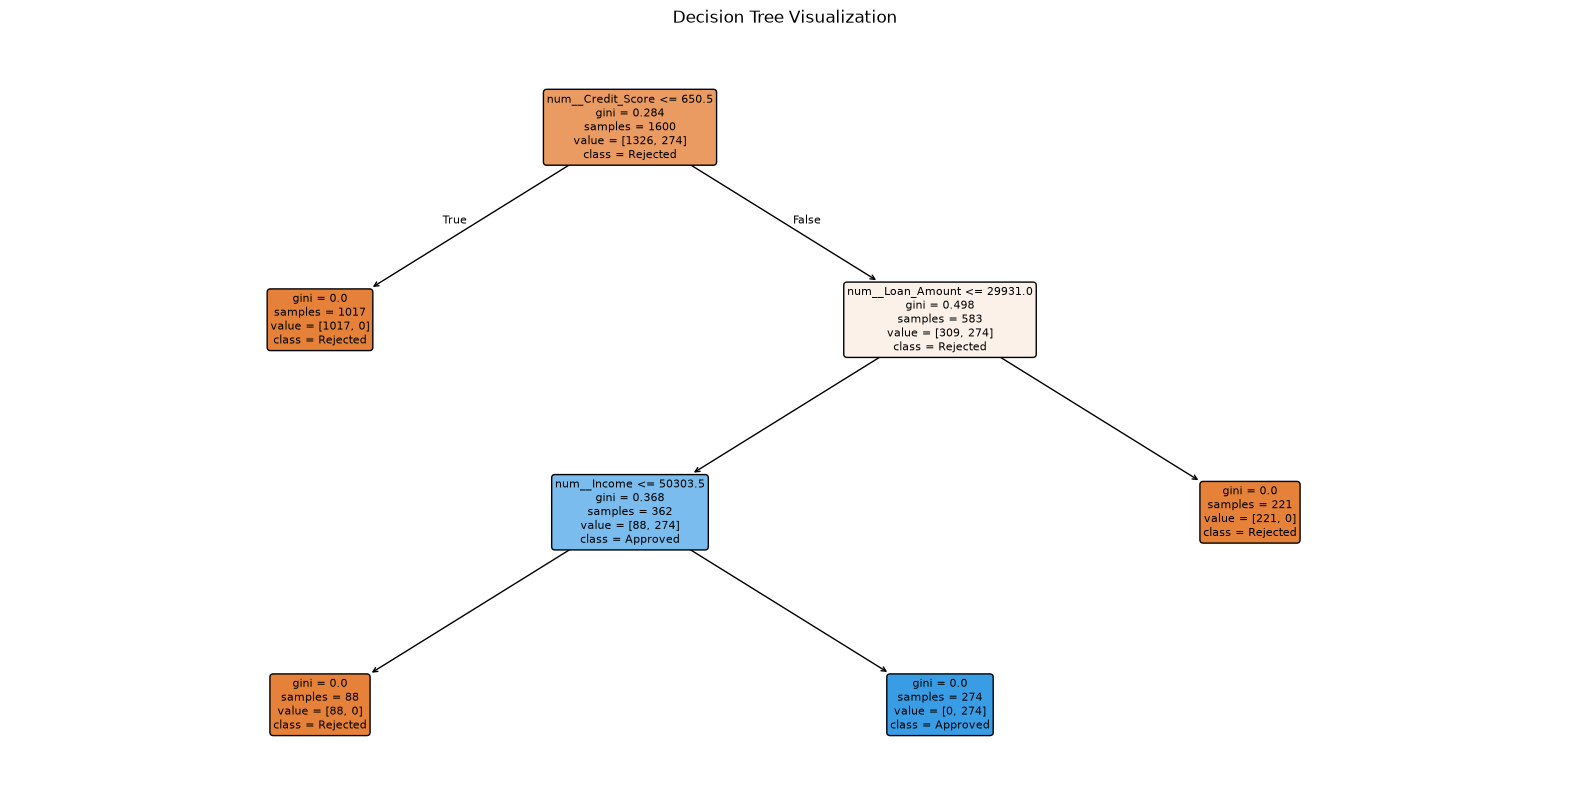

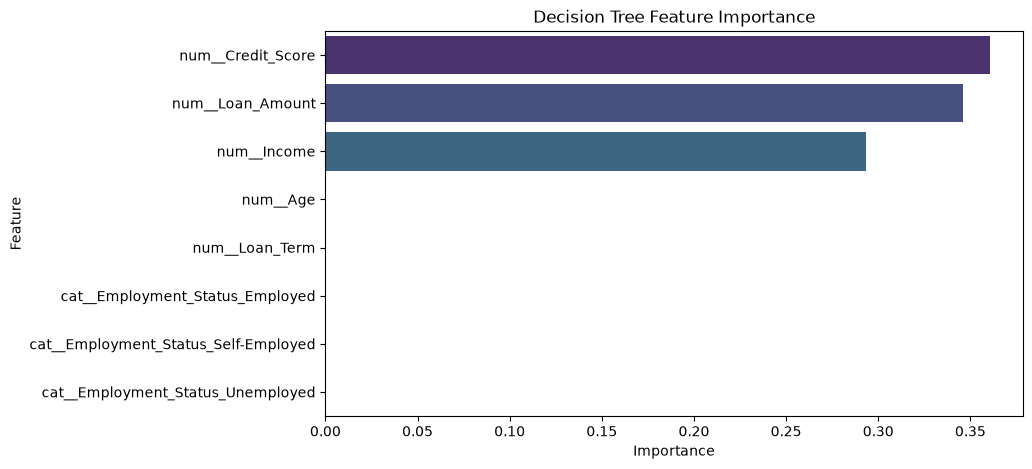


       PROJECT COMPLETED SUCCESSFULLY
Dataset: Loan Prediction Dataset
Total Records: 2000
Training Records: 1600
Testing Records: 400

Models Used:
1. Logistic Regression
2. Support Vector Machine
3. Decision Tree

Best Model by F1 Score: Decision Tree
Best F1 Score: 1.0
Best Accuracy: 1.0

Generated Files:
1. Loan_Prediction_Results.csv
2. Model_Performance_Comparison.csv

ALL OPERATIONS COMPLETED!


In [2]:

# ============================================================
# LOAN APPROVAL PREDICTION USING MACHINE LEARNING
# Algorithms: Logistic Regression, SVM, Decision Tree
# ============================================================

# 1. IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")


# 2. LOAD DATASET

df = pd.read_csv("loan_prediction_dataset.csv")

print("\nDataset Loaded Successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


# 3. DATA EXPLORATION

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nLoan Approval Distribution:")
print(df['Loan_Approved'].value_counts())


# 4. DATA PREPROCESSING

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing values
df = df.dropna()

# Separate features and target
X = df.drop('Loan_Approved', axis=1)
y = df['Loan_Approved']

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("\nNumerical Features:", numerical_features)
print("Categorical Features:", categorical_features)


# 5. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 6. FEATURE SCALING AND ENCODING

# Logistic Regression and SVM preprocessing
preprocessor_scaled = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

# Decision Tree preprocessing
preprocessor_tree = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ]
)

print("\nPreprocessing Pipeline Created!")


# 7. DEFINE MACHINE LEARNING MODELS

models = {
    'Logistic Regression': Pipeline([
        ('preprocessing', preprocessor_scaled),
        ('classifier', LogisticRegression(max_iter=2000))
    ]),

    'Support Vector Machine': Pipeline([
        ('preprocessing', preprocessor_scaled),
        ('classifier', SVC(
            kernel='rbf',
            probability=True,
            random_state=42
        ))
    ]),

    'Decision Tree': Pipeline([
        ('preprocessing', preprocessor_tree),
        ('classifier', DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ])
}


# 8. TRAIN AND EVALUATE MODELS

results = []
predictions = {}

for name, model in models.items():

    print("\nTraining:", name)

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    predictions[name] = y_pred

    # Calculate performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    probabilities = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, probabilities)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'ROC AUC': auc
    })

    print(name, "Training Completed!")


# 9. MODEL COMPARISON

results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
display(results_df.round(4))


# 10. ACCURACY COMPARISON GRAPH

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x='Model',
    y='Accuracy',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title("Accuracy Comparison of ML Models")
plt.ylabel("Accuracy")
plt.xlabel("Machine Learning Algorithms")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.show()


# 11. CONFUSION MATRICES

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, y_pred) in zip(axes, predictions.items()):

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()


# 12. CLASSIFICATION REPORTS

for name, y_pred in predictions.items():

    print("\n================================")
    print(name)
    print("================================")

    print(classification_report(
        y_test,
        y_pred,
        zero_division=0
    ))


# 13. DECISION TREE VISUALIZATION

tree_model = models['Decision Tree']

feature_names = (
    tree_model.named_steps['preprocessing']
    .get_feature_names_out()
)

plt.figure(figsize=(20, 10))

plot_tree(
    tree_model.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['Rejected', 'Approved'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Visualization")
plt.show()


# 14. FEATURE IMPORTANCE

importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': tree_model.named_steps[
        'classifier'
    ].feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=importance,
    x='Importance',
    y='Feature',
    hue='Feature',
    palette='viridis',
    legend=False
)

plt.title("Decision Tree Feature Importance")
plt.show()


# 15. PREDICT LOAN APPROVAL FOR TEST RECORDS

prediction_results = X_test.copy()

prediction_results['Actual Approval'] = y_test.values

for name, y_pred in predictions.items():
    prediction_results[name] = y_pred

prediction_results.to_csv(
    "Loan_Prediction_Results.csv",
    index=False
)

results_df.to_csv(
    "Model_Performance_Comparison.csv",
    index=False
)


# 16. FINAL PROJECT SUMMARY

best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("\n========================================")
print("       PROJECT COMPLETED SUCCESSFULLY")
print("========================================")

print("Dataset: Loan Prediction Dataset")
print("Total Records:", len(df))
print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nModels Used:")
print("1. Logistic Regression")
print("2. Support Vector Machine")
print("3. Decision Tree")

print("\nBest Model by F1 Score:", best_model['Model'])
print("Best F1 Score:", round(best_model['F1 Score'], 4))
print("Best Accuracy:", round(best_model['Accuracy'], 4))

print("\nGenerated Files:")
print("1. Loan_Prediction_Results.csv")
print("2. Model_Performance_Comparison.csv")

print("\nALL OPERATIONS COMPLETED!")
